import os, sys

# Doit etre defini AVANT le premier import torch
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")
if device.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("CPU uniquement — entrainement lent")


## Google Colab Setup

> **Executer uniquement sur Colab.** En local, passer cette cellule.

**Avant de lancer :**
1. `Runtime > Changer le type d'execution > GPU T4`
2. Uploader `colab_data.zip` sur ton Google Drive (generer avec `scripts/prepare_colab_upload.py`)


In [1]:
import os, sys

# Doit etre defini AVANT le premier import torch
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")
if device.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("CPU uniquement — entrainement lent")



Device : cuda
GPU    : NVIDIA GeForce RTX 5060 Laptop GPU
VRAM   : 8.5 GB


In [2]:
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

if is_colab():
    BASE = "/content/drive/MyDrive/Rakuten"
else:
    BASE = "C:\\Users\\veyss\\Nouveau dossier\\nov25_alt1_mle_rakuten"

print(f"BASE : {BASE}")

BASE : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten


In [3]:
if is_colab():
    from google.colab import drive
    drive.mount('/content/drive')
    print('Drive monte')
else:
    print('Local : pas besoin de monter Drive')


Local : pas besoin de monter Drive


In [4]:
import os, subprocess, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

def is_colab():
    try:
        import google.colab; return True
    except ImportError:
        return False

if is_colab():
    if subprocess.run(["nvidia-smi"], capture_output=True).returncode != 0:
        raise RuntimeError("GPU non disponible — Runtime > Changer le type d execution > GPU")

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")
if device.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")


Device : cuda
GPU    : NVIDIA GeForce RTX 5060 Laptop GPU
VRAM   : 8.5 GB


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import pickle, time, os
from tqdm import tqdm
from PIL import Image
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, classification_report
from sklearn.preprocessing import normalize


In [6]:
# BASE defini dans la cellule "Chemin BASE" ci-dessus
SPLIT_DIR     = os.path.join(BASE, "data", "split")
PROCESSED_DIR = os.path.join(BASE, "data", "processed")
MODELS_DIR    = os.path.join(BASE, "models")
RAW_DIR       = os.path.join(BASE, "data", "raw")
CACHE_DIR     = PROCESSED_DIR


train_split = pd.read_csv(os.path.join(SPLIT_DIR, "train.csv"))
val_split   = pd.read_csv(os.path.join(SPLIT_DIR, "val.csv"))
test_split  = pd.read_csv(os.path.join(SPLIT_DIR, "test.csv"))

y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
y_val   = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))
y_test  = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))

with open(os.path.join(MODELS_DIR, "label_encoder.pkl"), "rb") as f:
    le = pickle.load(f)
class_names = [str(c) for c in le.inverse_transform(range(27))]
print(f"Splits : train={len(train_split):,} | val={len(val_split):,} | test={len(test_split):,}")

Splits : train=59,185 | val=12,993 | test=12,738


### Pourquoi SentenceTransformer n'a pas besoin de preprocessing texte

Contrairement au TF-IDF qui travaille sur des sacs de mots, SentenceTransformer (`paraphrase-multilingual-mpnet-base-v2`) est un modele Transformer qui :

- **Gere nativement** les stopwords : il comprend le contexte syntaxique
- **N'a pas besoin de lemmatisation** : "jouets", "jouet", "jouer" ont des representations proches dans l'espace vectoriel
- **Supporte le multilinguisme** (fr/en/de/es) sans traduction
- **Input** : `text_combined_raw` = designation + description nettoyees HTML uniquement (pas de suppression stopwords, pas de lowercasing force)

> `text_combined` (avec lemmatisation) degrade les performances ST car il perd le contexte syntaxique dont BERT a besoin.


### Etape 0 — Preparation texte (text_combined_raw) + Embeddings ST

> **A executer une seule fois** — les embeddings sont mis en cache dans `data/processed/X_st_*.npy`.


In [7]:
# ── Chargement text_combined_raw depuis les CSVs de split ────────────────
# text_combined_raw = designation + description, nettoyage HTML uniquement
# (sans lemmatisation ni stopwords — ST gere le contexte nativement)
#
# Les CSVs contiennent deja cette colonne depuis 01_baseline.ipynb (cell 107)
# Si colonne absente : relancer la cellule de split dans 01_baseline.ipynb

NEEDED_COL = "text_combined_raw"

if NEEDED_COL not in train_split.columns:
    print(f"COLONNE MANQUANTE : '{NEEDED_COL}' absente de train.csv")
    print("Solution : relancer la cellule 107 dans 01_baseline.ipynb")
    print("           puis re-uploader les CSVs sur Drive")
else:
    texts_train = train_split[NEEDED_COL].fillna("").tolist()
    texts_val   = val_split[NEEDED_COL].fillna("").tolist()
    texts_test  = test_split[NEEDED_COL].fillna("").tolist()
    print(f"Textes charges depuis split CSVs :")
    print(f"  train={len(texts_train):,} | val={len(texts_val):,} | test={len(texts_test):,}")
    print(f"  Exemple : {texts_train[0][:120]}")


Textes charges depuis split CSVs :
  train=59,185 | val=12,993 | test=12,738
  Exemple : plaque metal 30x20cm style émaillé aston martin db5 james bond


In [ ]:
# ── Encodage SentenceTransformer ─────────────────────────────────────────
# Cache automatique dans data/processed/
from sentence_transformers import SentenceTransformer

ST_MODEL = "intfloat/multilingual-e5-base" # "paraphrase-multilingual-mpnet-base-v2"
ST_TRAIN = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[10:]}_train.npy")
ST_VAL   = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[10:]}_val.npy")
ST_TEST  = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[10:]}_test.npy")

if os.path.exists(ST_TRAIN) and os.path.exists(ST_VAL) and os.path.exists(ST_TEST):
    X_txt_train = np.load(ST_TRAIN)
    X_txt_val   = np.load(ST_VAL)
    X_txt_test  = np.load(ST_TEST)
    print("Embeddings ST charges depuis cache.")
else:
    print(f"Calcul embeddings ST ({ST_MODEL})...")
    print("~20 min CPU | ~2 min GPU — progression ci-dessous")
    st_model = SentenceTransformer(ST_MODEL, device=str(device),model_kwargs={"torch_dtype": "float16"})
    X_txt_train = st_model.encode(
        texts_train, batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    X_txt_val   = st_model.encode(
        texts_val,   batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    X_txt_test  = st_model.encode(
        texts_test,  batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    np.save(ST_TRAIN, X_txt_train)
    np.save(ST_VAL,   X_txt_val)
    np.save(ST_TEST,  X_txt_test)
    print("Embeddings sauvegardes dans data/processed/")

print(f"ST embeddings : train={X_txt_train.shape} | val={X_txt_val.shape} | test={X_txt_test.shape}")
print(f"Norme L2 (verification) : {np.linalg.norm(X_txt_train[0]):.4f} (doit etre ~1.0)")


Calcul embeddings ST (intfloat/multilingual-e5-base)...
~20 min CPU | ~2 min GPU — progression ci-dessous


Batches: 100%|██████████| 200/200 [00:18<00:00, 10.77it/s]


Embeddings sauvegardes dans data/processed/
ST embeddings : train=(59185, 768) | val=(12993, 768) | test=(12738, 768)
Norme L2 (verification) : 1.0000 (doit etre ~1.0)


In [ ]:
# ── Chargement features TF-IDF (calculees dans notebook 01) ─────────
import scipy.sparse as sp

tfidf_train_path = os.path.join(PROCESSED_DIR, "X_tfidf_train.npz")
if os.path.exists(tfidf_train_path):
    X_tfidf_train = sp.load_npz(tfidf_train_path)
    X_tfidf_val   = sp.load_npz(os.path.join(PROCESSED_DIR, "X_tfidf_val.npz"))
    X_tfidf_test  = sp.load_npz(os.path.join(PROCESSED_DIR, "X_tfidf_test.npz"))
    print(f"TF-IDF charge : train={X_tfidf_train.shape}")
else:
    X_tfidf_train = X_tfidf_val = X_tfidf_test = None
    print("TF-IDF non trouve — relance notebook 01 pour le generer")


---
### Etape 1 — CONFIG experience (changer ici)


In [ ]:
# ╔══════════════════════════════════════════════════════════╗
# ║  CONFIG EXP 1 — modifier ici                            ║
# ╚══════════════════════════════════════════════════════════╝
EXPERIMENT = {
    "name"         : "exp1_st_clip_logreg",
    "description"  : "ST 768d + clip 512d + LogReg",
    "text_features": "sentence_transformer",
    "img_backbone" : "clip",    # resnet18 | resnet50 | clip | dinov2
    "img_frozen"   : True,
    "img_dim"      : 512,
    "classifier"   : "logreg",         # logreg | lightgbm | mlp
    "C"            : 1.0,
    "max_iter"     : 500,
    "use_tfidf"    : True,
    "fusion"       : "concat",         # concat | text_only | image_only
}
print(f"Experience : {EXPERIMENT['name']}")
print(f"Device     : {device}")


Experience : exp1_st_clip_logreg
Device     : cuda


### Etape 2 — Extraction features image

> Cache par backbone dans `data/processed/X_img_{backbone}_{split}.npy`.


In [11]:
backbone_name = EXPERIMENT["img_backbone"]

if backbone_name == "resnet18":
    backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    backbone.fc = torch.nn.Identity()
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

elif backbone_name == "resnet50":
    backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    backbone.fc = torch.nn.Identity()
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

elif backbone_name == "clip":
    from transformers import CLIPModel, CLIPProcessor
    _clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
    backbone = _clip.vision_model
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.48145466,0.4578275,0.40821073],
                    [0.26862954,0.26130258,0.27577711])])

elif backbone_name == "dinov2":
    from transformers import AutoModel
    backbone = AutoModel.from_pretrained("facebook/dinov2-base")
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

if EXPERIMENT["img_frozen"]:
    for p in backbone.parameters(): p.requires_grad = False
backbone.eval().to(device)
print(f"Backbone : {backbone_name} | frozen={EXPERIMENT['img_frozen']} | dim={EXPERIMENT['img_dim']}")


c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\veyss\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Backbone : clip | frozen=True | dim=512


In [12]:
class ImageDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.records   = df[["image_name","label"]].reset_index(drop=True)
        self.img_dir   = img_dir
        self.transform = transform
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        row  = self.records.iloc[idx]
        path = os.path.join(self.img_dir, row["image_name"])
        try:
            img = self.transform(Image.open(path).convert("RGB"))
        except Exception:
            img = torch.zeros(3, 224, 224)
        return img, int(row["label"])

def extract_img_features(df, split_name):
    cache = os.path.join(CACHE_DIR,
        f"X_img_{EXPERIMENT['img_backbone']}_{split_name}.npy")
    if os.path.exists(cache):
        print(f"{split_name} : cache charge"); return np.load(cache)
    loader = DataLoader(
        ImageDataset(df, os.path.join(SPLIT_DIR, split_name), img_transform),
        batch_size=64, shuffle=False, num_workers=0,
        pin_memory=(device.type=="cuda"))
    feats = []
    with torch.no_grad():
        for imgs, _ in tqdm(loader, desc=f"Extract {split_name}"):
            imgs = imgs.to(device)
            if EXPERIMENT["img_backbone"] == "clip":
                out = backbone(pixel_values=imgs).pooler_output
            elif EXPERIMENT["img_backbone"] == "dinov2":
                out = backbone(pixel_values=imgs).last_hidden_state[:,0,:]
            else:
                out = backbone(imgs)
            feats.append(out.cpu().numpy())
    X = np.vstack(feats)
    np.save(cache, X)
    print(f"{split_name} : {X.shape} -> {cache}")
    return X

X_img_train = extract_img_features(train_split, "train")
X_img_val   = extract_img_features(val_split,   "val")
X_img_test  = extract_img_features(test_split,  "test")
print(f"Image : train={X_img_train.shape} | val={X_img_val.shape} | test={X_img_test.shape}")


Extract train: 100%|██████████| 925/925 [12:02<00:00,  1.28it/s] 


train : (59185, 768) -> C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\X_img_clip_train.npy


Extract val: 100%|██████████| 204/204 [02:31<00:00,  1.34it/s]


val : (12993, 768) -> C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\X_img_clip_val.npy


Extract test: 100%|██████████| 200/200 [02:27<00:00,  1.36it/s]

test : (12738, 768) -> C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\X_img_clip_test.npy
Image : train=(59185, 768) | val=(12993, 768) | test=(12738, 768)


### Etape 3 — Fusion


In [13]:
from sklearn.preprocessing import normalize
import scipy.sparse as sp

X_img_train_n = normalize(X_img_train)
X_img_val_n   = normalize(X_img_val)
X_img_test_n  = normalize(X_img_test)

def _fuse(tfidf, txt, img):
    """Concatene TF-IDF sparse + ST dense + img dense -> dense."""
    parts = []
    if tfidf is not None and EXPERIMENT.get("use_tfidf", True):
        parts.append(tfidf.toarray() if sp.issparse(tfidf) else tfidf)
    parts.append(txt)
    if img is not None:
        parts.append(img)
    return np.hstack(parts)

fusion = EXPERIMENT["fusion"]
if fusion == "concat":
    X_train_f = _fuse(X_tfidf_train, X_txt_train, X_img_train_n)
    X_val_f   = _fuse(X_tfidf_val,   X_txt_val,   X_img_val_n)
    X_test_f  = _fuse(X_tfidf_test,  X_txt_test,  X_img_test_n)
elif fusion == "text_only":
    X_train_f = _fuse(X_tfidf_train, X_txt_train, None)
    X_val_f   = _fuse(X_tfidf_val,   X_txt_val,   None)
    X_test_f  = _fuse(X_tfidf_test,  X_txt_test,  None)
elif fusion == "image_only":
    X_train_f, X_val_f, X_test_f = X_img_train_n, X_img_val_n, X_img_test_n

use_tfidf = X_tfidf_train is not None and EXPERIMENT.get("use_tfidf", True)
print(f"Fusion [{fusion}] | TF-IDF={use_tfidf} | -> train={X_train_f.shape}")


Fusion [concat] -> train=(59185, 1536)


### Etape 4 — Entrainement


In [ ]:
classifier = EXPERIMENT["classifier"]
CLF_CACHE = os.path.join(MODELS_DIR,
    f"clf_{EXPERIMENT['name']}_{EXPERIMENT['text_features']}_{EXPERIMENT['img_backbone']}_{EXPERIMENT['classifier']}.pkl")

print(f"Entrainement : {classifier}")
t0 = time.time()

y_tr = np.array(y_train).astype(int).ravel()
y_va = np.array(y_val).astype(int).ravel()

if os.path.exists(CLF_CACHE):
    with open(CLF_CACHE, "rb") as _f: clf = pickle.load(_f)
    print(f"Modele charge depuis cache : {os.path.basename(CLF_CACHE)}")
else:
    if classifier == "logreg":
        from sklearn.linear_model import LogisticRegression
        clf = LogisticRegression(
            C=EXPERIMENT["C"], max_iter=EXPERIMENT["max_iter"],
            class_weight="balanced", solver="saga", n_jobs=-1, random_state=42,
            warm_start=True)
        for n_iter in [10, 25, 50, 100, EXPERIMENT["max_iter"]]:
            clf.set_params(max_iter=n_iter)
            clf.fit(X_train_f, y_tr)
            f1_tr = f1_score(y_tr, clf.predict(X_train_f), average="macro")
            f1_va = f1_score(y_va, clf.predict(X_val_f),   average="macro")
            print(f"  iter={n_iter:4d}  train_F1={f1_tr:.4f}  val_F1={f1_va:.4f}")

    elif classifier == "lightgbm":
        import lightgbm as lgb
        clf = lgb.LGBMClassifier(
            n_estimators=1000, learning_rate=0.05,
            num_leaves=31, min_child_samples=50,
            subsample=0.8, colsample_bytree=0.8,
            reg_lambda=2.0, class_weight="balanced",
            n_jobs=-1, random_state=42, verbose=-1)
        clf.fit(X_train_f, y_tr,
                eval_set=[(X_train_f, y_tr), (X_val_f, y_va)],
                eval_names=["train", "val"],
                callbacks=[
                    lgb.early_stopping(stopping_rounds=50, verbose=True),
                    lgb.log_evaluation(period=50),
                ])

    elif classifier == "mlp":
        from sklearn.neural_network import MLPClassifier
        clf = MLPClassifier(
            hidden_layer_sizes=(512, 256), activation="relu",
            max_iter=5, early_stopping=True, validation_fraction=0.1,
            random_state=42, verbose=True)
        clf.fit(X_train_f, y_tr)

    with open(CLF_CACHE, "wb") as _f: pickle.dump(clf, _f)
    print(f"Modele sauvegarde : {os.path.basename(CLF_CACHE)}")

print(f"Duree : {time.time()-t0:.1f}s")

Entrainement : logreg


In [ ]:
print(f"\nDuree totale : {time.time()-t0:.1f}s")
with open(CLF_CACHE, "wb") as _f:
    pickle.dump(clf, _f)
print(f"Modele sauvegarde : {os.path.basename(CLF_CACHE)}")


Duree totale : 2889.6s
Modele sauvegarde : clf_exp1_st_resnet50_logreg_sentence_transformer_resnet50_logreg.pkl


In [ ]:
# ── Ablation : Text-only vs Image-only vs Text+Image ─────────────────
# Repond a la question : est-ce que les images apportent vraiment ?
from sklearn.linear_model import LogisticRegression

X_img_n = {"train": X_img_train_n, "val": X_img_val_n}

modes = {
    "text_only" : (X_txt_train,                       X_txt_val),
    "image_only": (X_img_n["train"],                  X_img_n["val"]),
    "concat"    : (np.hstack([X_txt_train, X_img_n["train"]]),
                   np.hstack([X_txt_val,   X_img_n["val"]])),
}

y_tr_ab = np.array(y_train).astype(int).ravel()
y_va_ab = np.array(y_val).astype(int).ravel()

print(f"Ablation (LogReg C=1.0, max_iter=300)")
print(f"{'Mode':<15} {'Dim':<8} {'val F1 macro'}")
print("-" * 40)
ablation_results = {}
for name, (Xtr, Xva) in modes.items():
    lr = LogisticRegression(C=1.0, max_iter=300, class_weight="balanced",
                            solver="saga", n_jobs=-1, random_state=42)
    lr.fit(Xtr, y_tr_ab)
    f1 = f1_score(y_va_ab, lr.predict(Xva), average="macro")
    ablation_results[name] = f1
    print(f"{name:<15} {Xtr.shape[1]:<8} {f1:.4f}")

best = max(ablation_results, key=ablation_results.get)
gain = ablation_results["concat"] - ablation_results["text_only"]
print(f"Gain image sur text_only : {gain:+.4f}")
print(f"Meilleur mode : {best} ({ablation_results[best]:.4f})")

Ablation (LogReg C=1.0, max_iter=300)
Mode            Dim      val F1 macro
----------------------------------------
text_only       768      0.6925


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


image_only      2048     0.0012


: 

### Etape 5 — Evaluation


In [ ]:
preds_val  = clf.predict(X_val_f)
preds_test = clf.predict(X_test_f)
f1_val  = f1_score(y_val,  preds_val,  average="macro")
f1_test = f1_score(y_test, preds_test, average="macro")
print(f"F1 macro val  : {f1_val:.4f}")
print(f"F1 macro test : {f1_test:.4f}")
print("\n" + classification_report(y_test, preds_test, target_names=class_names))


c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


F1 macro val  : 0.7836
F1 macro test : 0.7781

              precision    recall  f1-score   support

          10       0.65      0.66      0.66       467
          40       0.74      0.75      0.75       376
          50       0.80      0.77      0.79       252
          60       0.93      0.79      0.85       125
        1140       0.72      0.78      0.75       401
        1160       0.96      0.94      0.95       593
        1180       0.71      0.39      0.51       115
        1280       0.58      0.57      0.58       731
        1281       0.60      0.49      0.54       311
        1300       0.80      0.92      0.85       757
        1301       0.95      0.87      0.91       121
        1302       0.70      0.65      0.67       374
        1320       0.77      0.73      0.75       486
        1560       0.77      0.75      0.76       761
        1920       0.86      0.90      0.88       646
        1940       0.85      0.92      0.88       120
        2060       0.72      0.75 

### Etape 5b — Interpretation


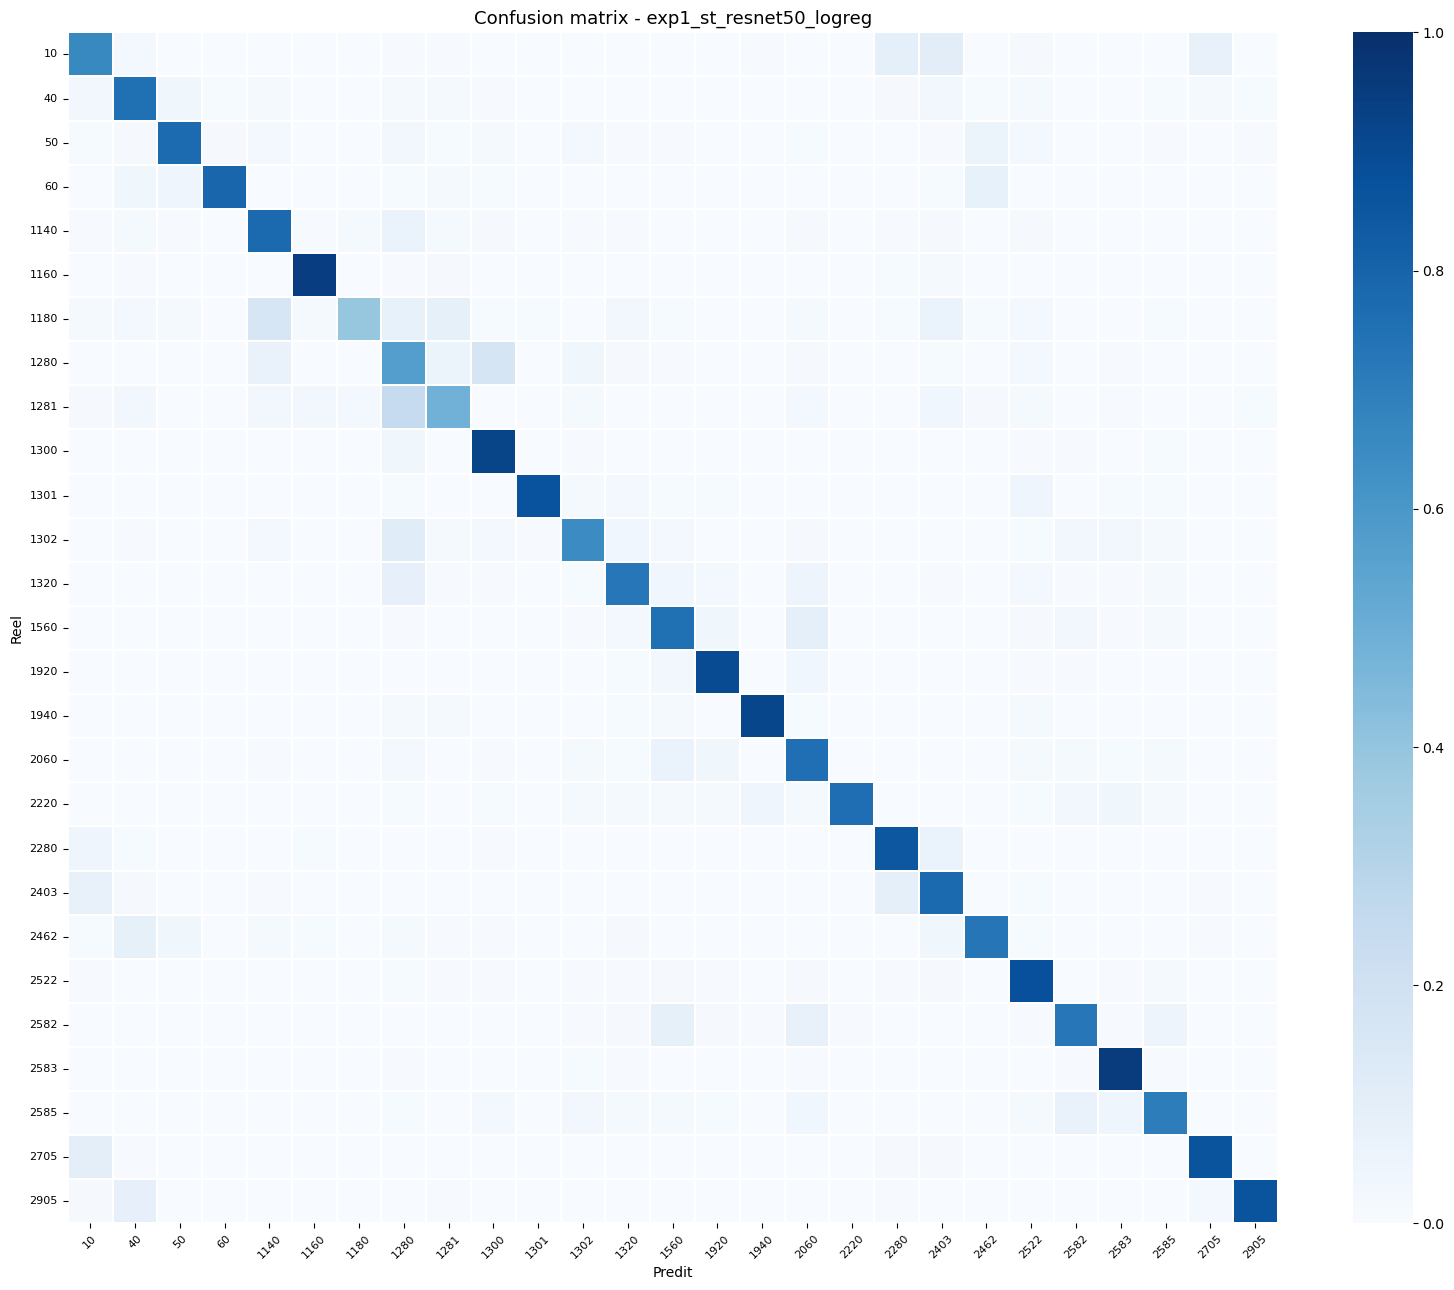

Top 5 confusions :
  1281                           -> 1280                           (25.1%)
  1280                           -> 1300                           (17.5%)
  1180                           -> 1140                           (16.5%)
  1302                           -> 1280                           (11.5%)
  10                             -> 2403                           (10.7%)


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, preds_test)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(cm_norm, annot=False, cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            ax=ax, linewidths=0.3, vmin=0, vmax=1)
ax.set_title(f"Confusion matrix - {EXPERIMENT['name']}", fontsize=13)
ax.set_xlabel("Predit"); ax.set_ylabel("Reel")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", rotation=0,  labelsize=8)
plt.tight_layout(); plt.show()
cm0 = cm_norm.copy(); np.fill_diagonal(cm0, 0)
idx = np.unravel_index(np.argsort(cm0, axis=None)[-5:], cm0.shape)
print("Top 5 confusions :")
for r, c in zip(idx[0][::-1], idx[1][::-1]):
    print(f"  {class_names[r]:<30} -> {class_names[c]:<30} ({cm0[r,c]*100:.1f}%)")


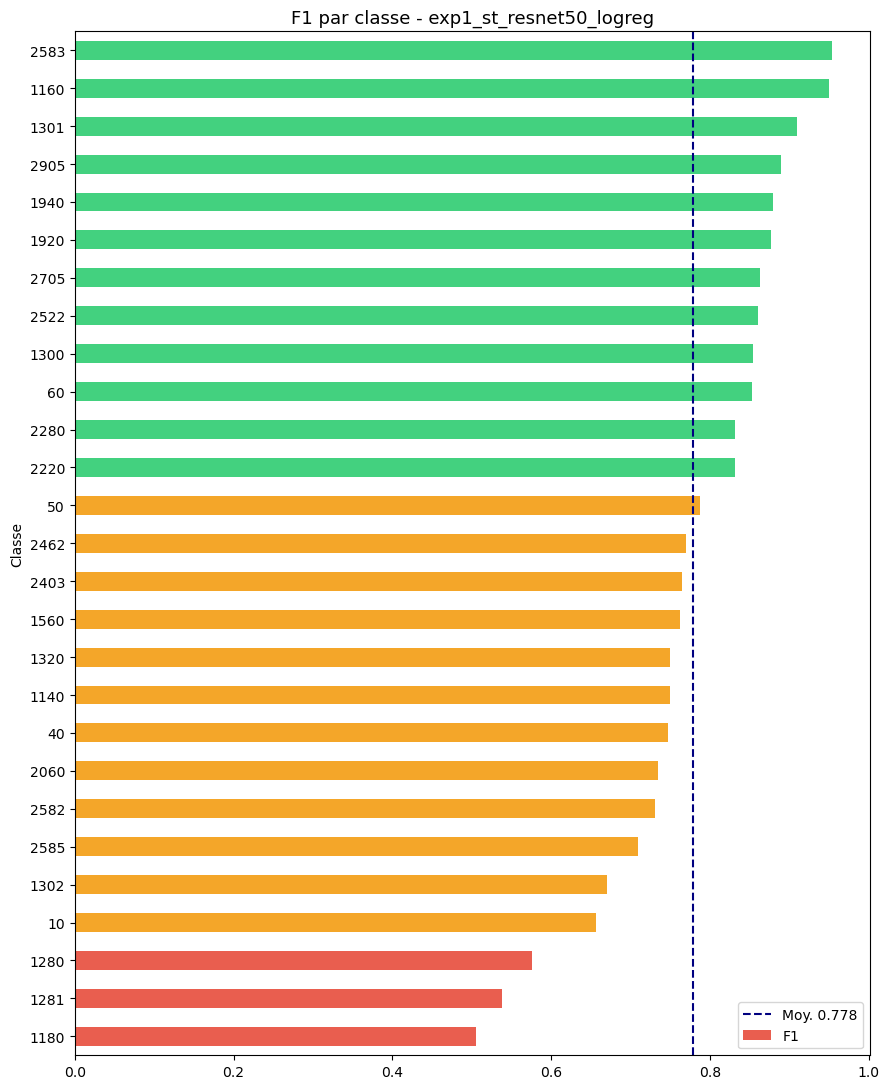

Classes F1 < 0.5 : []


In [ ]:
f1_per = f1_score(y_test, preds_test, average=None)
df_f1  = pd.DataFrame({"Classe": class_names, "F1": f1_per})\
           .set_index("Classe").sort_values("F1")
colors = ["#E74C3C" if v<0.6 else "#F39C12" if v<0.8 else "#2ECC71"
          for v in df_f1["F1"]]
fig, ax = plt.subplots(figsize=(9, 11))
df_f1["F1"].plot(kind="barh", ax=ax, color=colors, alpha=0.9)
ax.axvline(df_f1["F1"].mean(), color="navy", linestyle="--",
           label=f"Moy. {df_f1['F1'].mean():.3f}")
ax.set_title(f"F1 par classe - {EXPERIMENT['name']}", fontsize=13)
ax.legend(); plt.tight_layout(); plt.show()
print(f"Classes F1 < 0.5 : {df_f1[df_f1['F1']<0.5].index.tolist()}")


### Etape 6 — Resume


In [ ]:
print("\n" + "="*60)
print("RESUME EXPERIENCE")
print("="*60)
for k, v in EXPERIMENT.items():
    print(f"  {k:<16}: {v}")
print(f"  {'F1 macro val':<16}: {f1_val:.4f}")
print(f"  {'F1 macro test':<16}: {f1_test:.4f}")
print("="*60)



RESUME EXPERIENCE
  name            : exp1_st_resnet50_logreg
  description     : ST 768d + ResNet50 512d + LogReg
  text_features   : sentence_transformer
  img_backbone    : resnet50
  img_frozen      : True
  img_dim         : 512
  classifier      : lightgbm
  C               : 1.0
  max_iter        : 300
  fusion          : concat
  F1 macro val    : 0.7836
  F1 macro test   : 0.7781


In [ ]:
# ── Tableau de résultats complet ─────────────────────────────
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

preds_val  = clf.predict(X_val_f)
preds_test = clf.predict(X_test_f)

results = {
    "Experience"   : EXPERIMENT['name'],
    "Texte"        : EXPERIMENT['text_features'],
    "Image"        : EXPERIMENT['img_backbone'],
    "Fusion"       : EXPERIMENT['fusion'],
    "Classifieur"  : EXPERIMENT['classifier'],
    "F1 macro val" : round(f1_score(y_val,  preds_val,  average='macro'), 4),
    "F1 macro test": round(f1_score(y_test, preds_test, average='macro'), 4),
    "Accuracy test": round(accuracy_score(y_test, preds_test), 4),
    "F1 weighted"  : round(f1_score(y_test, preds_test, average='weighted'), 4),
    "Modele cache" : os.path.basename(CLF_CACHE),
}

df_results = pd.DataFrame([results])
print("\n" + "="*70)
print("RESULTATS")
print("="*70)
print(df_results.T.to_string(header=False))
print("="*70)

# Sauvegarde CSV des résultats
RESULTS_CSV = os.path.join(MODELS_DIR, f"experiments_{EXPERIMENT['name']}_results.csv")
if os.path.exists(RESULTS_CSV):
    df_existing = pd.read_csv(RESULTS_CSV)
    # Remplacer si experience deja presente, sinon ajouter
    mask = (
        (df_existing['Experience'] == results['Experience']) &
        (df_existing['Classifieur'] == results['Classifieur'])
    )
    if mask.any():
        df_existing.loc[mask] = pd.DataFrame([results]).values
        df_existing.to_csv(RESULTS_CSV, index=False)
        print(f"Resultats mis a jour dans {RESULTS_CSV}")
    else:
        pd.concat([df_existing, df_results], ignore_index=True).to_csv(RESULTS_CSV, index=False)
        print(f"Resultats ajoutes dans {RESULTS_CSV}")
else:
    df_results.to_csv(RESULTS_CSV, index=False)
    print(f"Resultats sauvegardes dans {RESULTS_CSV}")


c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



RESULTATS
Experience                                                    exp1_st_resnet50_logreg
Texte                                                            sentence_transformer
Image                                                                        resnet50
Fusion                                                                         concat
Classifieur                                                                  lightgbm
F1 macro val                                                                   0.7836
F1 macro test                                                                  0.7781
Accuracy test                                                                  0.7957
F1 weighted                                                                     0.794
Modele cache   clf_exp1_st_resnet50_logreg_sentence_transformer_resnet50_lightgbm.pkl
Resultats sauvegardes dans C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten\models\experiments_exp1_st_resnet50_logreg_resul